# 02 · Structure from Motion con COLMAP

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StevenFAP1815/project-reconstruction-3d/blob/main/notebooks/02_sfm_colmap.ipynb)

Reconstrucción dispersa de un objeto (criterios 4 y 5 de la rúbrica):

1. **Preprocesamiento:** nitidez de cada foto (varianza del Laplaciano) y
   descarte de fotos borrosas con un criterio cuantitativo.
2. **SfM incremental:** SIFT → emparejamiento con RANSAC → registro
   incremental, triangulación y bundle adjustment.
3. **Métricas:** % de fotos registradas (ref. ≥ 90 %), n.º de puntos 3D,
   longitud media de *track* y error de reproyección (ref. < 1 px).
4. **Geometría epipolar:** matriz F y líneas epipolares verificadas en un par.
5. **Trayectoria de captura:** posiciones de la cámara estimadas por SfM.
6. **Intrínsecos:** comparación entre la autocalibración de COLMAP y la
   calibración con tablero (`01_calibration.ipynb`).

El objeto se elige con `OBJECT` en la celda de parámetros; el resto del
notebook no cambia. **Entorno:** GPU (SIFT y emparejamiento en CUDA).

## 1. Entorno

In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/StevenFAP1815/project-reconstruction-3d.git"
REPO_DIR = Path("/content/project-reconstruction-3d")

if REPO_DIR.exists():
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=True)
else:
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))

# Python importa cada módulo una sola vez por sesión. Si esta sesión ya había
# cargado recon3d (una ejecución anterior), se descarta para que el siguiente
# import lea el código recién descargado y no una versión antigua en memoria.
for module in [name for name in sys.modules if name == "recon3d" or name.startswith("recon3d.")]:
    del sys.modules[module]

COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "--short", "HEAD"],
                        capture_output=True, text=True).stdout.strip()
print("Código del repositorio en el commit", COMMIT)

Código del repositorio en el commit 4af6802


In [3]:
%pip install -q -r /content/project-reconstruction-3d/requirements-colab.txt

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cuml-cu13 26.6.0 requires cuda-toolkit[cublas,cufft,curand,cusolver,cusparse]==13.*, but you have cuda-toolkit 12.9.2.0 which is incompatible.
libcuml-cu13 26.6.0 requires cuda-toolkit[cublas,cufft,curand,cusolver,cusparse]==13.*, but you have cuda-toolkit 12.9.2.0 which is incompatible.
cudf-cu13 26.6.0 requires cuda-toolkit[nvcc,nvrtc]==13.*, but you have cuda-toolkit 12.9.2.0 which is incompatible.
libcugraph-cu13 26.6.0 requires cuda-toolkit[cublas,curand,cusolver,cusparse,nvrtc]==13.*, but you have cuda-toolkit 12.9.2.0 which is incompatible.
libraft-cu13 26.6.0 requires cuda-toolkit[cublas,curand,cusolver,cusparse]==13.*, but you have cuda-toolkit 12.9.2.0 which is incompatible.
torch 2.14.1+cu130 requires cuda-toolkit[cublas,cudart,cufft,cufile,cupti,curand,cusolver,cusparse,nvjitlink,nvrtc,nvtx]==13.0.3; p

## 2. Parámetros

In [4]:
OBJECT = "caja-carton-leche"   # uno de recon3d.paths.OBJECTS
METHOD = "colmap"
SEED = 42
MAX_FEATURES = 8192            # máximo de puntos SIFT por foto
BLUR_RATIO = 0.35              # borrosa si nitidez < 0.35 x mediana del objeto
FILTER_BLURRY = True           # descartar las fotos borrosas antes de SfM

In [5]:
import json
import time

import pycolmap

from recon3d.dataset import extract_object_zip
from recon3d.paths import get_paths
from recon3d.reproducibility import set_seed
from recon3d.results import environment_info

set_seed(SEED)
paths = get_paths()
paths.create()

LOCAL_IMAGES = Path("/content/data") / OBJECT
images = extract_object_zip(paths.data_zip(OBJECT), LOCAL_IMAGES)
print(f"{OBJECT}: {len(images)} fotos")
print("pycolmap", pycolmap.__version__, "| CUDA:", pycolmap.has_cuda)
print("GPU:", environment_info()["gpu"])

caja-carton-leche: 73 fotos
pycolmap 4.2.1 | CUDA: True
GPU: Tesla T4


## 3. Preprocesamiento: fotos borrosas

La varianza del Laplaciano mide la cantidad de bordes nítidos. Como su valor
depende de la textura del objeto, el umbral es relativo: se marca como borrosa
una foto con menos de `BLUR_RATIO` veces la nitidez mediana del objeto.

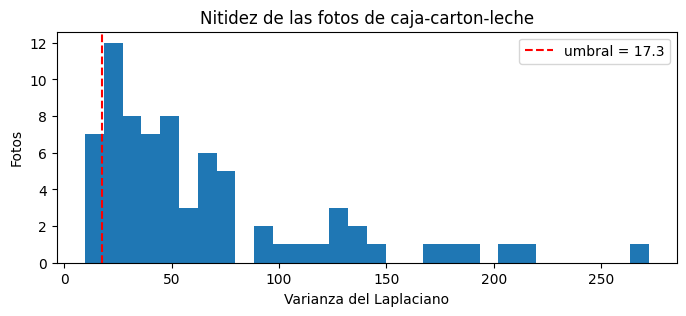

Fotos marcadas como borrosas: 5 de 73


,image,laplacian_var,blurry
11,IMG_20261113_015649.jpg,9.593817,True
45,IMG_20261113_020405.jpg,15.204742,True
18,IMG_20261113_015736.jpg,15.253252,True
47,IMG_20261113_020410.jpg,15.909058,True
44,IMG_20261113_020358.jpg,16.324162,True
8,IMG_20261113_015509.jpg,17.856155,False
66,IMG_20261113_020742.jpg,18.052540,False
17,IMG_20261113_015734.jpg,19.718256,False


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from recon3d.preprocessing import flag_blurry, laplacian_variance

start_total = time.perf_counter()
sharpness = {path.name: laplacian_variance(path) for path in images}
blurry = flag_blurry(sharpness, ratio=BLUR_RATIO)
threshold = BLUR_RATIO * np.median(list(sharpness.values()))

sharpness_df = pd.DataFrame(
    {"image": list(sharpness), "laplacian_var": list(sharpness.values())}
).sort_values("laplacian_var")
sharpness_df["blurry"] = sharpness_df["image"].isin(blurry)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sharpness_df["laplacian_var"], bins=30)
ax.axvline(threshold, color="red", linestyle="--", label=f"umbral = {threshold:.1f}")
ax.set_xlabel("Varianza del Laplaciano")
ax.set_ylabel("Fotos")
ax.set_title(f"Nitidez de las fotos de {OBJECT}")
ax.legend()
plt.show()

print(f"Fotos marcadas como borrosas: {len(blurry)} de {len(images)}")
sharpness_df.head(8)

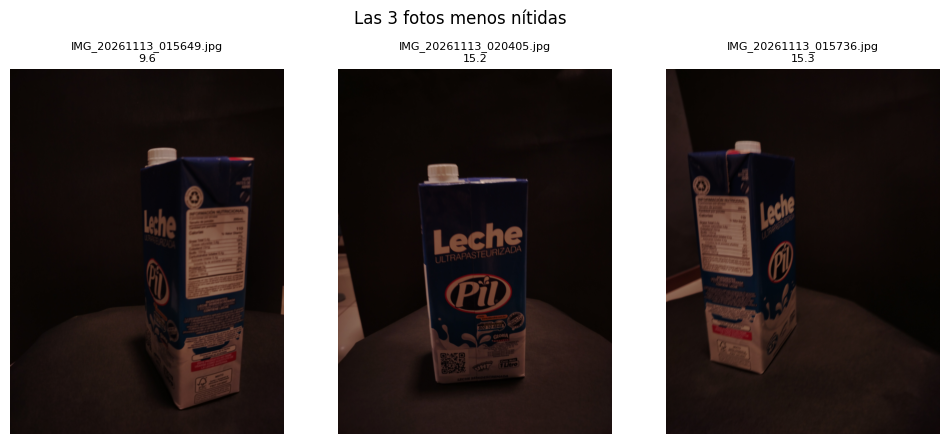

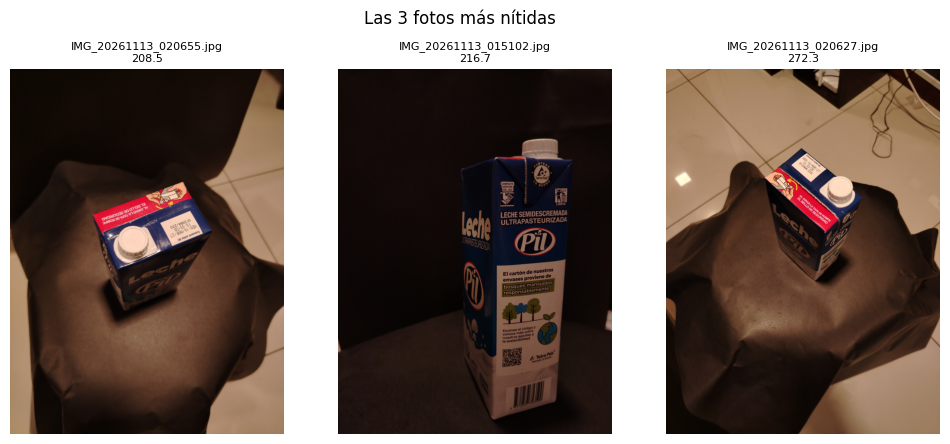

In [7]:
import cv2

def show(paths_to_show, title):
    fig, axes = plt.subplots(1, len(paths_to_show), figsize=(4 * len(paths_to_show), 5))
    for ax, name in zip(np.atleast_1d(axes), paths_to_show):
        image = cv2.cvtColor(cv2.imread(str(LOCAL_IMAGES / name)), cv2.COLOR_BGR2RGB)
        ax.imshow(image)
        ax.set_title(f"{name}\n{sharpness[name]:.1f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()

show(list(sharpness_df["image"].head(3)), "Las 3 fotos menos nítidas")
show(list(sharpness_df["image"].tail(3)), "Las 3 fotos más nítidas")

In [8]:
# Carpeta de trabajo con las fotos que entran a SfM (enlaces, no copias).
WORK = Path("/content/work") / OBJECT / METHOD
SFM_IMAGES = WORK / "images"
if SFM_IMAGES.exists():
    for link in SFM_IMAGES.iterdir():
        link.unlink()
SFM_IMAGES.mkdir(parents=True, exist_ok=True)

used = [p for p in images if not (FILTER_BLURRY and p.name in blurry)]
for path in used:
    (SFM_IMAGES / path.name).symlink_to(path)
print(f"Fotos que entran a SfM: {len(used)} de {len(images)}")

Fotos que entran a SfM: 68 de 73


## 4. SfM incremental

| Etapa | Qué hace |
|---|---|
| Extracción | SIFT por foto; una sola cámara compartida con modelo `SIMPLE_RADIAL` (f, cx, cy, k). |
| Emparejamiento | Todos los pares (exhaustivo) + verificación geométrica con RANSAC. |
| Mapeo | Par inicial → registro por PnP → triangulación → bundle adjustment. |

In [9]:
from recon3d.sfm import run_sfm, sfm_stats

rec, timings, n_models = run_sfm(SFM_IMAGES, WORK / "colmap", max_features=MAX_FEATURES)
stats = sfm_stats(rec, n_images=len(used))

print(rec.summary())
print(f"Modelos generados: {n_models} (1 = todas las fotos en un único modelo)")
for key, value in {**timings, **stats}.items():
    print(f"{key:>30}: {value:.2f}" if isinstance(value, float) else f"{key:>30}: {value}")

print()
print("Registradas ≥ 90 %:", "OK" if stats["registered_pct"] >= 90 else "NO")
print("Error de reproyección < 1 px:", "OK" if stats["mean_reprojection_error_px"] < 1 else "NO")

Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 43
	num_reg_frames = 43
	num_images = 43
	num_points3D = 5931
	num_observations = 29579
	mean_track_length = 4.98719
	mean_observations_per_image = 687.884
	mean_reprojection_error = 1.11282
Modelos generados: 2 (1 = todas las fotos en un único modelo)
                  extraction_s: 118.91
                    matching_s: 50.74
                     mapping_s: 50.63
                       total_s: 220.28
                      n_images: 68
                  n_registered: 43
                registered_pct: 63.24
                    n_points3d: 5931
             mean_track_length: 4.99
    mean_reprojection_error_px: 1.11
   mean_observations_per_image: 687.90

Registradas ≥ 90 %: NO
Error de reproyección < 1 px: NO


## 5. Geometría epipolar en un par

Se reproduce el núcleo de SfM con OpenCV en dos fotos consecutivas: SIFT,
prueba de razón de Lowe y estimación de la matriz fundamental F con RANSAC.
Cada punto de la foto 1 define una **línea epipolar** en la foto 2 sobre la
que debe estar su correspondiente (x₂ᵀ F x₁ = 0).

In [10]:
from recon3d.geometry import epipolar_distances

name1, name2 = used[0].name, used[1].name
SCALE = 1600 / 4000   # trabajar a 1600 px de lado para ir rápido
img1 = cv2.resize(cv2.imread(str(LOCAL_IMAGES / name1)), None, fx=SCALE, fy=SCALE)
img2 = cv2.resize(cv2.imread(str(LOCAL_IMAGES / name2)), None, fx=SCALE, fy=SCALE)
gray1, gray2 = (cv2.cvtColor(i, cv2.COLOR_BGR2GRAY) for i in (img1, img2))

sift = cv2.SIFT_create(nfeatures=4000)
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)
knn = cv2.BFMatcher().knnMatch(des1, des2, k=2)
good = [m for m, n in knn if m.distance < 0.8 * n.distance]
pts1 = np.float32([kp1[m.queryIdx].pt for m in good])
pts2 = np.float32([kp2[m.trainIdx].pt for m in good])

F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC, 1.0, 0.999)
inliers = mask.ravel().astype(bool)
distances = epipolar_distances(pts1[inliers], pts2[inliers], F)
print(f"SIFT: {len(kp1)} y {len(kp2)} puntos | tras Lowe: {len(good)} | "
      f"inliers RANSAC: {inliers.sum()} ({100 * inliers.mean():.0f} %)")
print(f"Distancia media de los inliers a su línea epipolar: {distances.mean():.3f} px")
print("F =\n", F)

SIFT: 658 y 948 puntos | tras Lowe: 306 | inliers RANSAC: 223 (73 %)
Distancia media de los inliers a su línea epipolar: 0.327 px
F =
 [[ 4.30260668e-07  4.36456455e-06 -4.65572379e-03]
 [-2.78380391e-06  2.53655986e-07 -2.89471924e-03]
 [ 2.83144567e-03  1.41981115e-03  1.00000000e+00]]


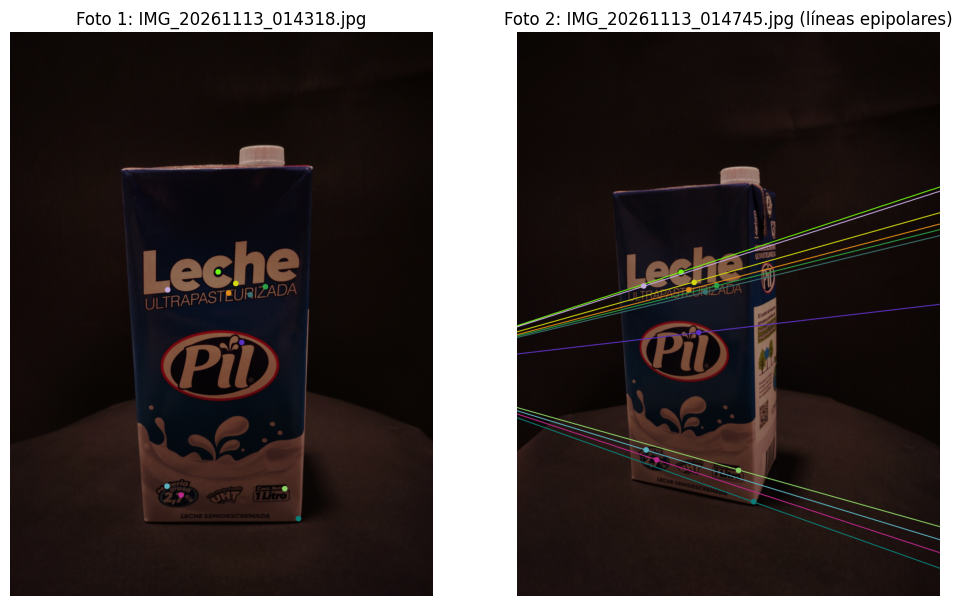

In [11]:
rng = np.random.default_rng(SEED)
sample = rng.choice(np.flatnonzero(inliers), size=min(12, inliers.sum()), replace=False)
lines = cv2.computeCorrespondEpilines(pts1[sample].reshape(-1, 1, 2), 1, F).reshape(-1, 3)

vis1, vis2 = img1.copy(), img2.copy()
width = vis2.shape[1]
for (a, b, c), p1, p2 in zip(lines, pts1[sample], pts2[sample]):
    color = tuple(int(v) for v in rng.integers(0, 255, 3))
    x0, y0 = 0, int(-c / b)
    x1, y1 = width, int(-(c + a * width) / b)
    cv2.line(vis2, (x0, y0), (x1, y1), color, 2)
    cv2.circle(vis2, tuple(int(v) for v in p2), 8, color, -1)
    cv2.circle(vis1, tuple(int(v) for v in p1), 8, color, -1)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))
axes[0].imshow(cv2.cvtColor(vis1, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Foto 1: {name1}")
axes[1].imshow(cv2.cvtColor(vis2, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Foto 2: {name2} (líneas epipolares)")
for ax in axes:
    ax.axis("off")
plt.show()

## 6. Trayectoria de captura y nube dispersa

Las posiciones de la cámara salen de las poses estimadas por SfM. Como la
orientación de la escena es arbitraria, se usa PCA para encontrar el plano de
las órbitas (vista desde arriba) y la dirección vertical (alturas).

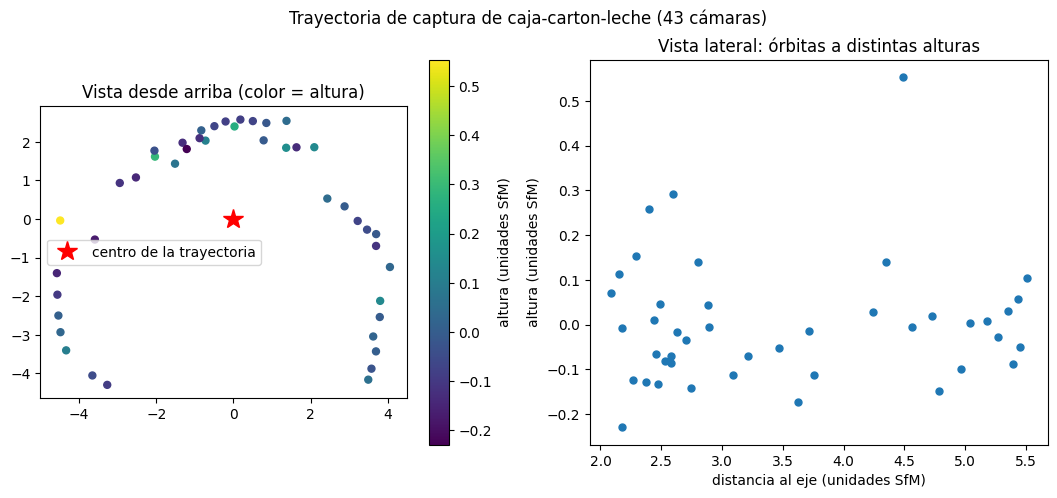

In [12]:
from recon3d.geometry import trajectory_frame
from recon3d.sfm import camera_centers

names, centers = camera_centers(rec)
coords, axes = trajectory_frame(centers)
radius = np.hypot(coords[:, 0], coords[:, 1])

fig, (ax_top, ax_side) = plt.subplots(1, 2, figsize=(13, 5))
sc = ax_top.scatter(coords[:, 0], coords[:, 1], c=coords[:, 2], cmap="viridis", s=25)
ax_top.plot(0, 0, "r*", markersize=15, label="centro de la trayectoria")
ax_top.set_aspect("equal")
ax_top.set_title("Vista desde arriba (color = altura)")
ax_top.legend()
fig.colorbar(sc, ax=ax_top, label="altura (unidades SfM)")

ax_side.scatter(radius, coords[:, 2], s=25)
ax_side.set_xlabel("distancia al eje (unidades SfM)")
ax_side.set_ylabel("altura (unidades SfM)")
ax_side.set_title("Vista lateral: órbitas a distintas alturas")
plt.suptitle(f"Trayectoria de captura de {OBJECT} ({len(names)} cámaras)")
plt.show()

In [13]:
import plotly.graph_objects as go

xyz = np.array([p.xyz for p in rec.points3D.values()])
rgb = np.array([p.color for p in rec.points3D.values()])
keep = np.random.default_rng(SEED).choice(len(xyz), size=min(40000, len(xyz)), replace=False)

fig = go.Figure([
    go.Scatter3d(x=xyz[keep, 0], y=xyz[keep, 1], z=xyz[keep, 2], mode="markers",
                 marker=dict(size=1.5, color=[f"rgb({r},{g},{b})" for r, g, b in rgb[keep]]),
                 name="puntos 3D"),
    go.Scatter3d(x=centers[:, 0], y=centers[:, 1], z=centers[:, 2], mode="markers",
                 marker=dict(size=4, color="red"), name="cámaras"),
])
fig.update_layout(height=650, scene=dict(aspectmode="data"),
                  title=f"Nube dispersa de {OBJECT}: {len(xyz)} puntos")
fig.show()

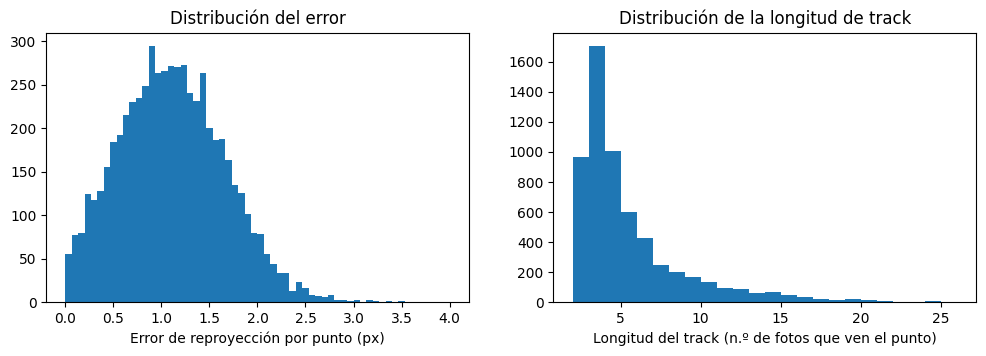

In [14]:
errors = np.array([p.error for p in rec.points3D.values()])
tracks = np.array([p.track.length() for p in rec.points3D.values()])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))
ax1.hist(errors, bins=60, range=(0, 4))
ax1.set_xlabel("Error de reproyección por punto (px)")
ax1.set_title("Distribución del error")
ax2.hist(tracks, bins=range(2, min(tracks.max(), 40) + 2))
ax2.set_xlabel("Longitud del track (n.º de fotos que ven el punto)")
ax2.set_title("Distribución de la longitud de track")
plt.show()

## 7. Intrínsecos: autocalibración vs. calibración con tablero

COLMAP estima la focal a partir del EXIF y la refina con bundle adjustment
(autocalibración). Se compara con la K obtenida con el tablero.

In [15]:
from recon3d.calibration import load_calibration

camera = next(iter(rec.cameras.values()))
f_sfm, cx_sfm, cy_sfm, k_sfm = camera.params  # modelo SIMPLE_RADIAL
comparison = {"f_sfm_px": f_sfm, "cx_sfm_px": cx_sfm, "cy_sfm_px": cy_sfm, "k1_sfm": k_sfm}

calibration_file = paths.calibration_results / "calibration.json"
if calibration_file.exists():
    K_cal, dist_cal, size_cal = load_calibration(calibration_file)
    fx, fy, cx, cy = K_cal[0, 0], K_cal[1, 1], K_cal[0, 2], K_cal[1, 2]
    comparison.update({"fx_cal_px": fx, "fy_cal_px": fy, "cx_cal_px": cx, "cy_cal_px": cy,
                       "k1_cal": dist_cal[0]})
    table = pd.DataFrame({
        "SfM (autocalibración)": [f_sfm, f_sfm, cx_sfm, cy_sfm],
        "Tablero": [fx, fy, cx, cy],
    }, index=["fx", "fy", "cx", "cy"])
    table["diferencia %"] = 100 * (table.iloc[:, 0] - table.iloc[:, 1]) / table.iloc[:, 1]
    display(table.round(2))
else:
    print("No hay calibration.json en Drive: ejecutar antes 01_calibration.ipynb.")
    print(comparison)

,SfM (autocalibración),Tablero,diferencia %
fx,2871.96,2851.93,0.70
fy,2871.96,2851.66,0.71
cx,1500.00,1504.55,-0.30
cy,2000.00,2010.97,-0.55


## 8. Guardar resultados

En `results/<objeto>/colmap/` de Drive:

- `sparse/`: modelo COLMAP completo (lo reutilizan MVS y los métodos de IA).
- `sparse.ply`: nube dispersa coloreada.
- `poses.npz`: rotaciones, traslaciones, centros e intrínsecos.
- `sharpness.csv`: nitidez de cada foto y si se descartó.
- `meta.json`: registro de la corrida.

In [16]:
from recon3d.results import write_meta
from recon3d.sfm import save_sparse_results

run_dir = paths.run_dir(OBJECT, METHOD)
saved = save_sparse_results(rec, run_dir)
sharpness_df.to_csv(run_dir / "sharpness.csv", index=False)

meta_path = write_meta(
    run_dir,
    object_name=OBJECT,
    method=METHOD,
    n_images=len(images),
    n_registered=rec.num_reg_images(),
    runtime_s=time.perf_counter() - start_total,
    seed=SEED,
    scale_factor=None,  # se calculará en la etapa de escala métrica
    extra={
        "max_features": MAX_FEATURES,
        "blur_ratio": BLUR_RATIO,
        "filter_blurry": FILTER_BLURRY,
        "blurry_images": blurry,
        "n_images_used": len(used),
        "n_models": n_models,
        "timings_s": {k: round(v, 2) for k, v in timings.items()},
        "stats": stats,
        "intrinsics": {k: float(v) for k, v in comparison.items()},
        "epipolar_pair": {"images": [name1, name2], "n_inliers": int(inliers.sum()),
                          "mean_distance_px": round(float(distances.mean()), 4)},
    },
)
for path in [*saved.values(), run_dir / "sharpness.csv", meta_path]:
    print(path)

/content/drive/MyDrive/project-reconstruction-3d/results/caja-carton-leche/colmap/sparse
/content/drive/MyDrive/project-reconstruction-3d/results/caja-carton-leche/colmap/sparse.ply
/content/drive/MyDrive/project-reconstruction-3d/results/caja-carton-leche/colmap/poses.npz
/content/drive/MyDrive/project-reconstruction-3d/results/caja-carton-leche/colmap/sharpness.csv
/content/drive/MyDrive/project-reconstruction-3d/results/caja-carton-leche/colmap/meta.json


## Siguiente paso

- Revisar las métricas frente a las referencias de la rúbrica (≥ 90 %
  registradas, error < 1 px) y anotarlas en el informe.
- Repetir con los demás objetos cambiando `OBJECT`.
- Descargar `results/<objeto>/colmap/meta.json` (y `sharpness.csv`) al
  repositorio local; los `.ply` y `.npz` se quedan en Drive.
- Siguiente etapa: reconstrucción densa (MVS), malla y escala métrica.